<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>


# ITGE275: Economics
## Session 3: The Production Engine – Supply, Costs, and Profit Maximization
---
### 👦 Student Information 👧

**Your name:** Qimin Zhu
**ID:** 6888143

---

### **1. Introduction: The Firm as a System**

We have studied the Consumer. Now we turn to the **Producer** (The Firm).  
In Computer Science terms, a Firm is a system that takes **Inputs** and processes them into **Outputs**.

* **Inputs ($x$):** Factors of Production (Labor, Capital, Raw Materials).
* **Function ($f$):** The Production Function (Technology/Process).
* **Output ($y$):** Goods and Services.

**The Goal:** Maximize Profit ($\pi$).
$$ \pi = \text{Total Revenue} - \text{Total Cost} $$

In [9]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation, rc
from scipy.optimize import minimize
import ipywidgets as widgets
from IPython.display import display, HTML

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. The Production Function (Cobb-Douglas)**

How exactly do inputs turn into outputs? Economists use the **Cobb-Douglas Production Function**, a mathematical model that is surprisingly accurate for manufacturing and tech alike.

$$ Y = A \cdot L^\alpha \cdot K^\beta $$

* **$Y$:** Output (Quantity produced).
* **$A$:** Total Factor Productivity (Technology/Efficiency).
* **$L$:** Labor (Input 1).
* **$K$:** Capital (Input 2).
* **$\alpha, \beta$:** Output elasticities. 
    * If $\alpha + \beta = 1$, we have **Constant Returns to Scale** (doubling inputs doubles outputs).
    * If $\alpha > \beta$, the industry is **Labor Intensive**.

#### **Case Study: The Bubble Tea Franchise**
You are opening a Bubble Tea stall. 
* **Labor ($L$):** Staff members.
* **Capital ($K$):** Sealing machines and shakers.

In [10]:
def cobb_douglas(L, K, A=1.0, alpha=0.5, beta=0.5):
    """
    Calculates production output Y based on Labor and Capital.
    """
    return A * (L ** alpha) * (K ** beta)

def plot_production_isoquants(alpha, beta):
    """
    Plots 'Isoquants' - lines representing equal levels of output for different combinations of L and K.
    This is like a topographic map of production.
    """
    # Create a grid of Labor and Capital values
    l_range = np.linspace(1, 20, 100)
    k_range = np.linspace(1, 20, 100)
    L_grid, K_grid = np.meshgrid(l_range, k_range)
    
    # Calculate Output (Z-axis)
    Y_grid = cobb_douglas(L_grid, K_grid, alpha=alpha, beta=beta)
    
    # Plotting
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Contour plot (Heatmap style)
    contour = ax.contourf(L_grid, K_grid, Y_grid, cmap='viridis', levels=20)
    fig.colorbar(contour, label='Output (Cups of Tea per Hour)')
    
    ax.set_title(f'Production Function ($alpha={alpha}, beta={beta}$)', fontsize=14)
    ax.set_xlabel('Labor (Staff Count)')
    ax.set_ylabel('Capital (Machines)')
    
    plt.show()

# Interactive Simulation
print("Adjust Alpha and Beta to see how the 'Technology' changes.")
print("High Alpha = Labor is more important (Service industry).")
print("High Beta = Capital is more important (Automated factory).")

style = {'description_width': 'initial'}
widgets.interactive(plot_production_isoquants,
                    alpha=widgets.FloatSlider(min=0.1, max=0.9, step=0.1, value=0.5, description='Alpha (Labor Elasticity)', style=style),
                    beta=widgets.FloatSlider(min=0.1, max=0.9, step=0.1, value=0.5, description='Beta (Capital Elasticity)', style=style))

Adjust Alpha and Beta to see how the 'Technology' changes.
High Alpha = Labor is more important (Service industry).
High Beta = Capital is more important (Automated factory).


interactive(children=(FloatSlider(value=0.5, description='Alpha (Labor Elasticity)', max=0.9, min=0.1, style=S…

### **3. Cost Structure: Fixed, Variable, and Marginal**

Profit isn't just about producing; it's about producing **efficiently**.

* **Fixed Costs (FC):** Costs that don't change with output (Rent, Business License).
* **Variable Costs (VC):** Costs that increase with output (Wages, Milk, Tea Leaves).
* **Total Cost (TC):** $FC + VC$.
* **Average Total Cost (ATC):** Cost per unit ($TC / Q$).
* **Marginal Cost (MC):** The cost of producing **one more** unit.

#### **The Golden Rule: MR = MC**
A firm should keep producing as long as the revenue from the next unit (Marginal Revenue) is greater than the cost of producing it (Marginal Cost). Profit is maximized when $MR = MC$.

In [11]:
# === Animation: The Optimal Scale ===
# We will visualize why the Marginal Cost curve always intersects the 
# Average Total Cost curve at its minimum point.

fig, ax = plt.subplots()
plt.close() # Prevent double plotting

# Production Quantity Range
q = np.linspace(1, 20, 100)

# Define Cost Functions
# Let TC = 50 + 2q^2 (Fixed Cost = 50, Variable Cost increases quadratically due to diminishing returns)
fixed_cost = 50
variable_cost = 2 * (q ** 2)
total_cost = fixed_cost + variable_cost

atc = total_cost / q             # Average Total Cost
mc = 4 * q                       # Marginal Cost (Derivative of TC)

def animate_costs(frame):
    ax.clear()
    
    # Draw the curves up to the current frame
    current_q = q[:frame+1]
    current_atc = atc[:frame+1]
    current_mc = mc[:frame+1]
    
    ax.plot(current_q, current_atc, color='blue', linewidth=2, label='Average Total Cost (ATC)')
    ax.plot(current_q, current_mc, color='red', linewidth=2, label='Marginal Cost (MC)')
    
    # Highlight the intersection (Efficiency Point)
    # Mathematically, ATC is minimized where MC = ATC
    min_atc_idx = np.argmin(atc)
    min_q = q[min_atc_idx]
    min_cost = atc[min_atc_idx]
    
    if frame >= min_atc_idx:
        ax.plot(min_q, min_cost, 'ko', markersize=10)
        ax.annotate('Optimal Scale\n(Min ATC)', xy=(min_q, min_cost), xytext=(min_q+2, min_cost+20),
                    arrowprops=dict(facecolor='black', shrink=0.05))

    ax.set_title('Cost Structure Analysis', fontsize=14)
    ax.set_xlabel('Quantity Produced')
    ax.set_ylabel('Cost ($)')
    ax.set_ylim(0, 100)
    ax.set_xlim(0, 20)
    ax.legend()
    ax.grid(True)

anim = animation.FuncAnimation(fig, animate_costs, frames=len(q), interval=50)
rc('animation', html='jshtml')
anim

### **4. Optimization: Minimizing Costs with Scipy**

In the real world, you have a **Target Output** (e.g., "We need to serve 100 customers/hour"). Your job is to achieve that target at the **Lowest Cost**.

This is a constrained optimization problem:
* **Minimize:** $Cost = (Wage \cdot L) + (Rent \cdot K)$
* **Subject to:** $A \cdot L^\alpha \cdot K^\beta = Target$

We will use `scipy.optimize.minimize` to find the perfect balance of Staff ($L$) and Machines ($K$).

In [15]:
# === The Optimization Engine ===

def optimize_production(target_output, wage, machine_rent, alpha=0.5, beta=0.5):
    """
    Finds the optimal L and K to produce 'target_output' at minimum cost.
    """
    
    # 1. Objective Function: Total Cost
    def cost_function(inputs):
        L, K = inputs
        return (wage * L) + (machine_rent * K)
    
    # 2. Constraint: Production must equal Target
    def production_constraint(inputs):
        L, K = inputs
        # Constraint form: f(x) = 0
        # So: Actual_Production - Target = 0
        return cobb_douglas(L, K, alpha=alpha, beta=beta) - target_output
    
    # 3. Initial Guess (Start with 10 staff, 10 machines)
    initial_guess = [10, 10]
    
    # 4. Run Optimizer
    cons = ({'type': 'eq', 'fun': production_constraint})
    bounds = ((0.1, None), (0.1, None)) # L and K must be positive
    
    result = minimize(cost_function, initial_guess, constraints=cons, bounds=bounds)
    
    return result

# Run a Test Case
wage_rate = 30     # $15/hour per staff
rental_rate = 30   # $30/hour per machine
target_cups = 100  # Target: 100 cups/hour

opt_res = optimize_production(target_cups, wage_rate, rental_rate)

opt_L = opt_res.x[0]
opt_K = opt_res.x[1]
min_cost = opt_res.fun

print(f"--- Optimization Results ---")
print(f"Target Output: {target_cups} cups")
print(f"Wage: ${wage_rate}, Machine Rent: ${rental_rate}")
print(f"Optimal Labor (Staff):    {opt_L:.2f}")
print(f"Optimal Capital (Machines): {opt_K:.2f}")
print(f"Minimum Total Cost:       ${min_cost:.2f}")
print(f"Ratio K/L: {opt_K/opt_L:.2f}")

--- Optimization Results ---
Target Output: 100 cups
Wage: $30, Machine Rent: $30
Optimal Labor (Staff):    100.00
Optimal Capital (Machines): 100.00
Minimum Total Cost:       $6000.00
Ratio K/L: 1.00


### **5. Real World Data: Industrial Trends**

Let's look at synthetic data representing the **Industrial Production Index (IPI)**, similar to data released by the Office of Industrial Economics (OIE) in Thailand. This tracks the "Supply" capability of the manufacturing sector.

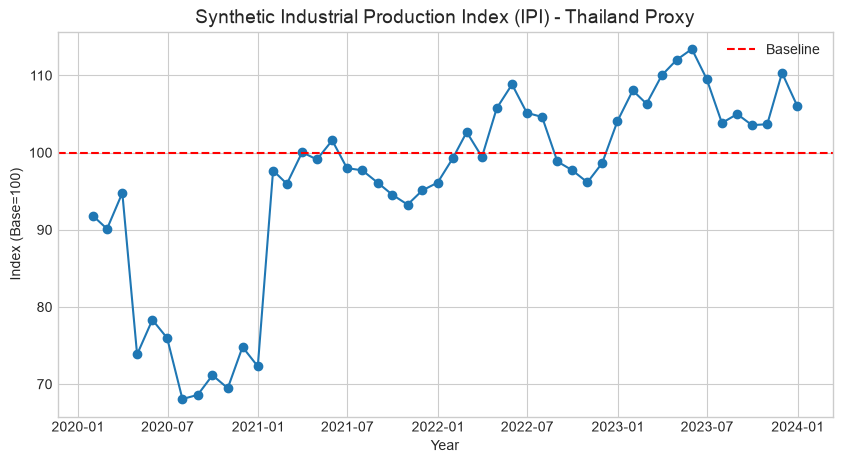

In [13]:
# Synthetic Data Generation (Mimicking OIE Thailand IPI Data)
dates = pd.date_range(start='2020-01-01', periods=48, freq='ME')

# Simulate a Covid dip and recovery trend
trend = np.linspace(90, 110, 48)
seasonality = 5 * np.sin(np.arange(48) * (2 * np.pi / 12))
shock = np.zeros(48)
shock[3:12] = -20 # Covid Shock in 2020

ipi_values = trend + seasonality + shock + np.random.normal(0, 2, 48)

df_ipi = pd.DataFrame({'Date': dates, 'IPI': ipi_values})

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(df_ipi['Date'], df_ipi['IPI'], marker='o', linestyle='-')
plt.title('Synthetic Industrial Production Index (IPI) - Thailand Proxy', fontsize=14)
plt.ylabel('Index (Base=100)')
plt.xlabel('Year')
plt.axhline(100, color='red', linestyle='--', label='Baseline')
plt.legend()
plt.grid(True)
plt.show()

---
## **6. 🏡 Homework Assignment 📝**

**Objective:** Use the Optimization Engine to solve a business strategy problem.

#### **Question 1: The Minimum Wage Hike**
Imagine the government increases the Minimum Wage, causing your Labor Cost to **Double**.

1.  **Baseline:** Run the `optimize_production` function with `wage=15` and `machine_rent=30`. Record the Optimal L and Optimal K.
2.  **Shock:** Run the function again with `wage=30` (Doubled) and `machine_rent=30` (Unchanged).
3.  **Analysis:**
    * How did the optimal amount of Labor change?
    * How did the optimal amount of Capital change?
    * Calculate the Capital-to-Labor Ratio ($K/L$) for both cases. Did the firm become more "Automated"? 

# === HOMEWORK SPACE: QUESTION 1 ===
# Write your code here to calculate the Baseline vs Shock scenarios.

# Case 1: Baseline (Wage=15, Rent=30)
    Optimal Labor (Staff):    141.42
    Optimal Capital (Machines): 70.71
    Minimum Total Cost:       $4242.64
    Ratio K/L: 0.50

# Case 2: Wage Hike (Wage=30, Rent=30)
    Optimal Labor (Staff):    100.00
    Optimal Capital (Machines): 100.00
    Minimum Total Cost:       $6000.00
    Ratio K/L: 1.00

# Compare results
    1. The optimal amount of labor increase
    2. When the Machine Rate incresase, the optimal labor cost decrease, but the K/L ratio and the Minimum Total Cost increase.
    3. Since the Raito is high, the firm is become more Automated.

#### **Question 2: Opportunity Cost in Production**
Explain the concept of **Opportunity Cost** in the context of a factory that has limited floor space. If they choose to produce **Product A** (Bubble Tea) instead of **Product B** (Coffee), what is the opportunity cost? (Do not answer with "Money").

*(Write your answers in the Markdown cell below)*

The implicit cost (opportunity cost) varies base on the product owner chooes to produce, because the different produce means the different raw materials, packaging materials, and machine that required.